### **<u> I. Import des données <u>**

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import wbgapi as wb
import statsmodels.formula.api as smf
from pathlib import Path
from functools import reduce

np.random.seed(123)

from modules.Fonctions import *


### Constantes

metrics = ["Number", "Percent", "Rate"]
colonness_GBD = ["location_id", "location_name", "cause_id", "cause_name", "metric_id", "metric_name", "year", "value","upper_bound", "lower_bound"]
causes_generales = [["All causes", 1, [294]],["Malignant neoplasm", 2, [1012, 459, 489]], ["Major cardiovascular diseases", 3,[491]], ["Liver diseases, cirrhosis", 4, [521]], ["Pneumonia and influenza", 5, [322]], ["Motor vehicle accidents", 6, [689, 688]],["Suicide", 7, [718]], ["Other accidents", 8, [696]], ["Homicide", 9, [724, 945,854]]]
numero_agg = [1012, 459, 489, 689, 688, 724, 945, 854] # numeros des causes aggrégées
numero_non_agg = [294,491,521,322,718,696] # numeros des causes non aggrégées 

countries = ["AUS", "AUT", "BEL", "CAN", "CHL", "COL", "CRI", "CZE", "DNK", "EST", "FIN", "FRA", "DEU", "GRC", "HUN", "ISL", "IRL", "ISR", "ITA",
             "JPN", "KOR", "LVA", "LTU", "LUX", "MEX", "NLD", "NZL", "NOR", "POL", "PRT", "SVK", "SVN", "ESP", "SWE", "CHE", "TUR", "GBR", "USA"]

indicateurs_vers_croissance = {
    "Taux_chômage": "Croissance_taux_chômage",
    "Taux_chômage_F": "Croissance_chômage_F",
    "Taux_chômage_H": "Croissance_chômage_H",
    "PIB/hab_ppa": "Croissance_PIB_hab_ppa",
    "Population": "Croissance_population",
}

code_vers_label = {
    "SL.UEM.TOTL.ZS": "Taux_chômage",
    "SL.UEM.TOTL.FE.ZS": "Taux_chômage_F",
    "SL.UEM.TOTL.MA.ZS": "Taux_chômage_H",
    "NY.GDP.PCAP.PP.KD": "PIB/hab_ppa",    
    "NY.GNP.PCAP.PP.KD": "RNB/hab_ppa",
    "SP.POP.TOTL": "Population",
    "SP.POP.65UP.TO.ZS": "Pourcentage_pop_65plus",
    "SH.XPD.GHED.GD.ZS": "Pourcentage_PIB_dépenses_santé"
}
#Création d'un tableau qui associe les codes pays à leurs noms complets en anglais
noms_pays = pd.DataFrame({
    "economy": countries,

    "location_name": ["Australia", "Austria", "Belgium", "Canada", "Chile", "Colombia", "Costa Rica",
    "Czechia", "Denmark", "Estonia", "Finland", "France", "Germany", "Greece",
    "Hungary", "Iceland", "Ireland", "Israel", "Italy", "Japan", "South Korea",
    "Latvia", "Lithuania", "Luxembourg", "Mexico", "Netherlands", "New Zealand",
    "Norway", "Poland", "Portugal", "Slovakia", "Slovenia", "Spain", "Sweden",
    "Switzerland", "Turkey", "United Kingdom", "United States"]
})

### <u> 1. Données du GBD

Nous utilisons les données de l'étude GBD (<i>Global Burden of Disease</i>), conduite par l'IHME (<i>Institute for Health Metrcis and Evaluation</i>), pour l'étude de la mortalité par causes dans les pays de l'OCDE. Avant de les importer directement, nous réarrangeons ces données dans un fichier excel :
- nous gardons toutes les catégories de causes de mort sauf la mort infantile car c'est pas le même mode de calcul
- nous ne conservons que les pays qui font partie de l'OCDE (38 pays au total), pour correspondre aux données fournies par World Bank 

Metric (metric_id et metric_name) correspondent à la manière de mesurer les causes de mortalités :
- number = nombres de morts
- percent = nombres de morts pour la cause en question/nombre total de mort dans le pays 
- rate : nombre de morts pour 100k habitants sur l'année
Les valeurs sont indiquées dans la colonne <i>value</i> ; la borne inférieure de l'intervalle de confiance à 95% dans la colonne <i>lower_bound</i>, et la borne supérieure dans la colonne <i>upper_bound</i>.

Le dataframe brute est ainsi construit de la manière suivante : 
- pour chaque pays : 3 x 14 x 44 = 1848 lignes
- 3 car il y a 3 métriques différentes 
- 14 car il y a 14 causes différentes
- 44 car l'étude se fait sur 44 années
- soit un total de 3 métriques x 14 causes x 44 années x 38 pays = 70224 lignes

In [3]:
# Url pour accéder au fichier CSV sur sspcloud
url = "https://minio.lab.sspcloud.fr/guigz/donnees_GBD_uniques.csv"

# Lecture directe du CSV
df_GBD = pd.read_csv(url, sep=";", encoding="latin-1", decimal=",")

df_GBD.head()

,population_group,measure,location_id,location_name,sex,age_name,cause_id,cause_name,metric_id,metric_name,year,value,upper_bound,lower_bound
0,All Population,Deaths,71,Australia,Both,All ages,294,All causes,1,Number,1980,108265.029600,108882.768100,107497.458600
1,All Population,Deaths,71,Australia,Both,All ages,491,Cardiovascular diseases,1,Number,1980,53252.643510,54951.178210,50203.750100
2,All Population,Deaths,71,Australia,Both,All ages,521,Cirrhosis and other chronic liver diseases,1,Number,1980,1390.286718,1469.238444,1314.555387
3,All Population,Deaths,71,Australia,Both,All ages,945,Conflict and terrorism,1,Number,1980,3.999771,4.397038,3.641975
4,All Population,Deaths,71,Australia,Both,All ages,724,Interpersonal violence,1,Number,1980,297.285701,330.648576,270.154420


Le code suivant permet d'obtenir le dataframe final du GBD (celui qui sera utilisé pour les études conduites ultérieurement). Deux idées sont mises en avant dans ce code. 
D'une part, il permet de faire corroborer les causes importées du GBD avec celles évoquées dans l'article <i> Deaths rise in good economic times:Evidence from the OECD </i> : ainsi, certaines causes ont été regroupées ensemble, pour ne former qu'une seule cause "générale". 
D'autre part, il permet de faire corroborer les années d'étude du GBD avec celles de l'étude du World Bank : ainsi, nous enlevons les données antérieures à 1991.
De plus, nous décidons de ne conserver que le taux (nombre de morts pour 100 000 habitants) comme métrique.

In [4]:
GBD_numeric=passage_en_numerique(df_GBD)
GBD_transforme = transformations_dataframe_GBD(GBD_numeric, causes_generales, metrics)
GBD_ordre_alphabete= ajout_numero_pays(GBD_transforme, "location_name", "location_id")

GBD_filtre = filtrage_dataframe(GBD_ordre_alphabete, 1991, 3).sort_values(by=["location_id","metric_id", "year", "cause_id"]).reset_index(drop=True)
GBD_final = GBD_filtre.drop(columns=["ecart_type", "var"])
GBD_final.head(9*33+1)

,location_name,cause_id,cause_name,metric_id,metric_name,year,value,upper_bound,lower_bound,location_id
0,Australia,1,All causes,3,Rate,1991,695.823881,700.496223,690.961278,1
1,Australia,2,Malignant neoplasm,3,Rate,1991,9.208670,9.558780,8.858560,1
2,Australia,3,Major cardiovascular diseases,3,Rate,1991,297.692038,309.566399,272.886999,1
3,Australia,4,"Liver diseases, cirrhosis",3,Rate,1991,7.445414,7.824939,7.008532,1
4,Australia,5,Pneumonia and influenza,3,Rate,1991,10.593496,11.203627,9.583196,1
...,...,...,...,...,...,...,...,...,...,...
293,Australia,6,Motor vehicle accidents,3,Rate,2023,10.983947,11.706293,10.261600,1
294,Australia,7,Suicide,3,Rate,2023,12.288987,13.068551,11.599252,1
295,Australia,8,Other accidents,3,Rate,2023,24.905355,27.991055,20.710593,1
296,Australia,9,Homicide,3,Rate,2023,0.953235,1.058731,0.847738,1


Le dataframe final des données du GBD est ainsi construit de la manière suivante : 
- 10 colonnes
- pour chaque pays : 9 x 33 = 297 lignes
- 9 car il n'y a plus que 9 causes différentes
- 33 car l'étude ne se fait plus que sur 33 années
- un total de 9 causes x 33 années x 38 pays = 11286 lignes

Tableau récapitulatif des correspondances entre nom et numéro d'identité des 38 pays 

In [5]:
locations = GBD_final[["location_id", "location_name"]].drop_duplicates()
locations

,location_id,location_name
0,1,Australia
297,2,Austria
594,3,Belgium
891,4,Canada
1188,5,Chile
1485,6,Colombia
1782,7,Costa Rica
2079,8,Czechia
2376,9,Denmark
2673,10,Estonia


Tableau récapitulatif des correspondances entre nom et numéro d'identité des 9 causes

In [6]:
causes = GBD_final[["cause_id", "cause_name"]].drop_duplicates()
causes

,cause_id,cause_name
0,1,All causes
1,2,Malignant neoplasm
2,3,Major cardiovascular diseases
3,4,"Liver diseases, cirrhosis"
4,5,Pneumonia and influenza
5,6,Motor vehicle accidents
6,7,Suicide
7,8,Other accidents
8,9,Homicide


### <u> 2. Données de la World Bank

API

In [7]:
df_en_long = wb.data.DataFrame(
        list(code_vers_label.keys()),
        economy=countries,
        time=range(1991, 2024),
        columns="series",        # met directement les indicateurs en colonnes
        numericTimeKeys=True     # met directement les années en int (1991, 1992...)
    ).reset_index().rename(columns={"time": "year"})

Création du tableau final des données de la WB de 15 colonnes et 33 années * 38 pays = 1254 lignes.

In [8]:
df_renomme = labelisation_dataframe_WB(df_en_long, noms_pays, "location_name", "location_id", code_vers_label)
df_final_WB = taux_croissance_dataframe_WB(df_renomme, indicateurs_vers_croissance, "location_id")

df_final_WB.head(2*33+1)

,year,PIB/hab_ppa,RNB/hab_ppa,Pourcentage_PIB_dépenses_santé,Taux_chômage_F,Taux_chômage_H,Taux_chômage,Pourcentage_pop_65plus,Population,location_name,location_id,Croissance_taux_chômage,Croissance_chômage_F,Croissance_chômage_H,Croissance_PIB_hab_ppa,Croissance_population
0,1991,35670.667864,30292.797235,NaN,9.164,9.887,9.586,11.237463,17284036.0,Australia,1,NaN,NaN,NaN,NaN,NaN
1,1992,35426.284829,30129.075368,NaN,9.935,11.305,10.733,11.413523,17478635.0,Australia,1,11.965366,8.413357,14.342065,-0.685109,1.125889
2,1993,36533.146828,31003.190328,NaN,10.004,11.509,10.879,11.579359,17634808.0,Australia,1,1.360291,0.694514,1.804511,3.124409,0.893508
3,1994,37622.652477,31777.679986,NaN,9.370,9.983,9.724,11.724779,17805468.0,Australia,1,-10.616785,-6.337465,-13.259188,2.982239,0.967745
4,1995,38653.336678,32639.871049,NaN,8.111,8.743,8.473,11.846558,18004882.0,Australia,1,-12.865076,-13.436499,-12.421116,2.739531,1.119959
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
62,2020,60276.330770,61260.452136,8.710238,5.015,5.364,5.201,19.169789,8916864.0,Austria,2,14.057018,13.384581,14.639880,-6.706394,0.416040
63,2021,62968.853877,64007.465832,9.462125,6.403,6.508,6.459,19.462853,8955797.0,Austria,2,24.187656,27.676969,21.327368,4.466966,0.436622
64,2022,65694.459150,64044.877873,8.656315,4.797,5.163,4.992,19.789751,9041851.0,Austria,2,-22.712494,-25.081993,-20.666872,4.328498,0.960875
65,2023,64536.207631,63324.658902,8.532197,5.025,5.476,5.264,20.164020,9131761.0,Austria,2,5.448718,4.752971,6.062367,-1.763089,0.994376


### <u> 3. Merging des deux tableaux

In [9]:
df_final = pd.merge(GBD_final.drop(columns=["metric_id", "metric_name"]), df_final_WB.drop(columns=["location_name"]), on=["location_id", "year"], how="outer")
df_final = df_final.rename(columns={"value": "taux_mortalite"}) # renommer value en taux_mortalite
df_final = df_final[["location_name","location_id", "year", "cause_id", "cause_name", "taux_mortalite","upper_bound", "lower_bound","PIB/hab_ppa","RNB/hab_ppa", "Taux_chômage", "Taux_chômage_F", "Taux_chômage_H", "Population", "Pourcentage_pop_65plus", "Pourcentage_PIB_dépenses_santé", "Croissance_PIB_hab_ppa", "Croissance_taux_chômage", "Croissance_chômage_F", "Croissance_chômage_H", "Croissance_population"]] # on ordonne les colonnes
df_final.head(9*33+1)



,location_name,location_id,year,cause_id,cause_name,taux_mortalite,upper_bound,lower_bound,PIB/hab_ppa,RNB/hab_ppa,...,Taux_chômage_F,Taux_chômage_H,Population,Pourcentage_pop_65plus,Pourcentage_PIB_dépenses_santé,Croissance_PIB_hab_ppa,Croissance_taux_chômage,Croissance_chômage_F,Croissance_chômage_H,Croissance_population
0,Australia,1,1991,1,All causes,695.823881,700.496223,690.961278,35670.667864,30292.797235,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
1,Australia,1,1991,2,Malignant neoplasm,9.208670,9.558780,8.858560,35670.667864,30292.797235,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
2,Australia,1,1991,3,Major cardiovascular diseases,297.692038,309.566399,272.886999,35670.667864,30292.797235,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
3,Australia,1,1991,4,"Liver diseases, cirrhosis",7.445414,7.824939,7.008532,35670.667864,30292.797235,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
4,Australia,1,1991,5,Pneumonia and influenza,10.593496,11.203627,9.583196,35670.667864,30292.797235,...,9.164,9.887,17284036.0,11.237463,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
293,Australia,1,2023,6,Motor vehicle accidents,10.983947,11.706293,10.261600,60684.959620,59439.471532,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383
294,Australia,1,2023,7,Suicide,12.288987,13.068551,11.599252,60684.959620,59439.471532,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383
295,Australia,1,2023,8,Other accidents,24.905355,27.991055,20.710593,60684.959620,59439.471532,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383
296,Australia,1,2023,9,Homicide,0.953235,1.058731,0.847738,60684.959620,59439.471532,...,3.572,3.755,26659922.0,17.384025,7.659638,1.092514,-1.609442,-2.723312,-0.635089,2.464383


### **<u> II. Statistiques descriptives <u>**

#### <u> 1. Global Burden Disease ####

##### <u> a. Statistiques numériques

Ce paragraphe s'intéresse au résumé statistique des variables <i> value, upper_bound et lower_bound </i> pour la métrique <i> rate </i>, c'est à dire la nombre de morts pour 100 000 habitants sur l'année, pour le dataframe des données du GBD. On ne se préoccupe pas des autres colonnes, qui représentent le nom des pays ou de la mérique et ne sont par conséquent pas des nombres.

Tableau descriptif pour toutes les causes de mortalité 

In [10]:
variables_interet= ["value", "upper_bound", "lower_bound"]
    
GBD_final[GBD_final["cause_id"]==1][variables_interet].describe(include="all")

,value,upper_bound,lower_bound
count,1254.000000,1254.000000,1254.000000
mean,881.544608,889.385783,873.729974
std,251.534005,253.519335,249.638226
min,375.942414,380.727789,371.149540
25%,685.425650,695.278287,676.007500
50%,907.246538,915.324392,900.143726
75%,1019.013789,1026.163866,1012.073244
max,1760.616170,1774.001181,1747.873159


Dans un premier temps, on constate qu'il n'y a aucune valeur manquante : les trois variables ont le même count, donc toutes les observations sont renseignées.
De plus, pour chaque mesure, on a bien <i> lower_bound</i> < <i> value</i> < <i> upper_bound </i> : il y a donc cohérence des bornes.
Ensuite, la médiane de <i> value</i> (907) est assez proche de la moyenne (881) et l'écart type (252) représente 29% de cette dernière : la majorité des valeurs sont proches de la moyenne, cette dernière est donc représentative. 
Enfin, les intervalles d'incertitude sont très étroits : les estimations sont donc très précises.


##### <u> b. Graphes

Tout d'abord, nous étudions l'évolution du taux de mortalité, toutes causes confondues, en fonction des années, pour une sélection de 8 pays.

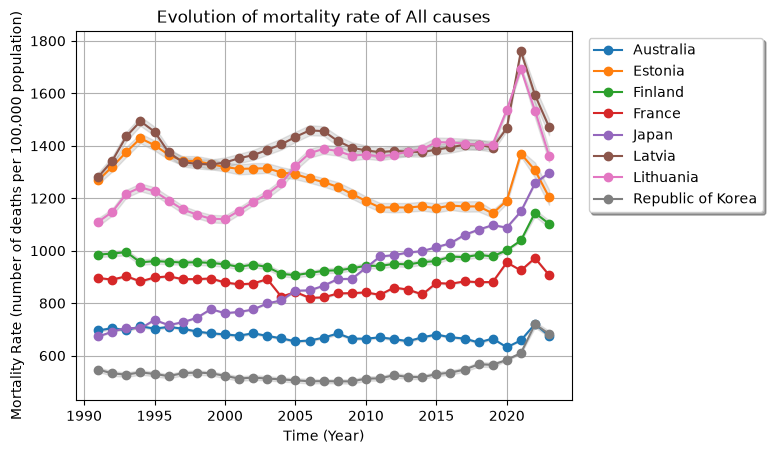

In [11]:
plot_dataframe_multiple_countries_GBD(df_final,1,[1,10,11,12,20,21,22,30]) #All causes

Les pays se répartissent en trois groupes distincts.
Dans un premier temps, les pays baltes (Lettonie, Lituanie, Estonie), qui ont un taux de mortalité (pour 100 000 habitants), toutes causes confondues, supérieur à 1000. L'évolution du taux de mortalité y est fluctuant : un pic en 1994 pour les trois pays, sûrement dû au choc de la transition post-soviétique, et un pic en 2006 pour la Lettonie et la Lituanie.
Dans un second temps, les pays européens et la Corée du Sud, qui ont un taux de mortalité, toutes causes confondues, inférieur à 1000. L'évolution du taux y est stable, voire en baisse, jusqu'aux années 2020. Pour ces deux groupes, on remarque également un pic de mortalité pour les années 2020, caractéristique de la pandémie du Covid-19.
Dans un troisième temps, le Japon, dont le taux de mortalité double entre 1991 (environ 700) et 2023 (environ 1300). cela peut être expliqué par le fait que la population japonaise est vieille, et donc de plus en plus de personnes décèdent.

A présent, nous affinons notre étude, en ne considérant comme cause de mortalité que le suicide.

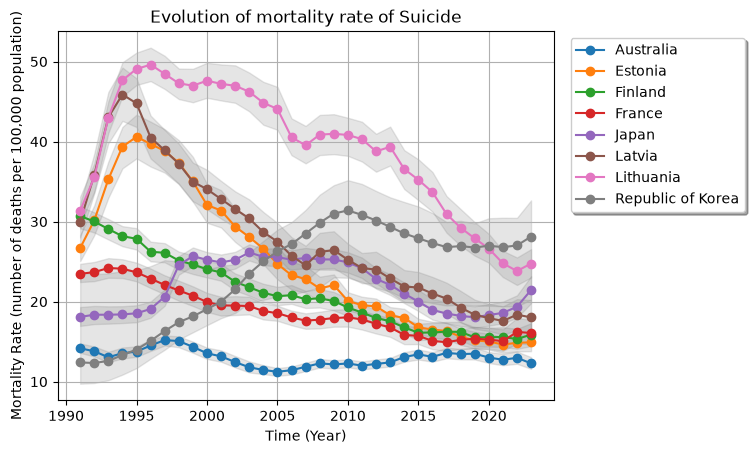

In [12]:
plot_dataframe_multiple_countries_GBD(df_final,7,[1,10,11,12,20,21,22,30]) #Suicide

Tout d'abord, on retrouve une tendance similaire pour les pays baltes : le taux de suicide y est plus élevé que dans les autres pays et atteint son pic vers les années 1994/1995 dans les trois pays, encore une fois possiblement expliqué par la transition post-soviétique. Après ce pic, le taux de mortalité diminue continuement, jusqu'à passer en dessous de celui de 1991.
Ensuite, la Finlande et la France suivent la même trajectoire décroissante, susceptible d'être expliquée par l'amélioration de la prise en charge psychiatrique, notamment dans les pays européens.
Enfin, le taux de mortalité de la Corée du Sud suit une évolution opposé. En effet, on remarque une augmentation des suicides au cours des années : on passe de 12 suicides pour 100 000 habitants en 1991 à 28 en 2023, réflètant certainement l'augmentation de la pression académique et économique.

Pour terminer cette section, nous nous intéressons ici en particulier au cancer comme cause de mortalité.

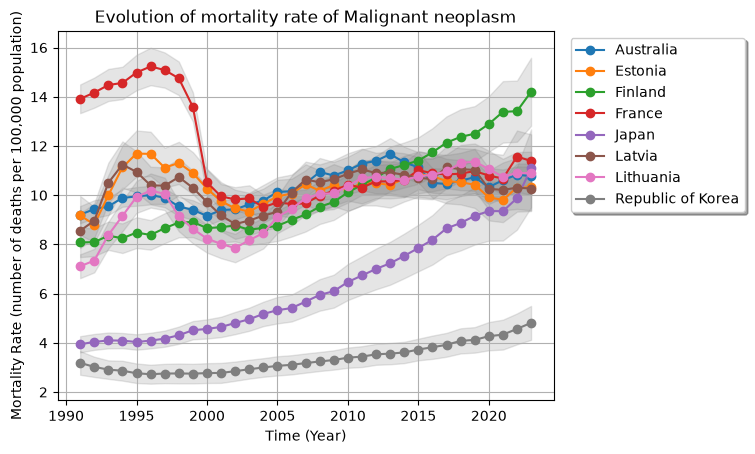

In [13]:
plot_dataframe_multiple_countries_GBD(df_final,2,[1,10,11,12,20,21,22,30]) #Homicide

En observe une convergence progressive des pays à partir des années 2000, sûrement provoqué par un vieillissement de la population des pays de l'OCDE. Les pays baltes connaissent un faible pic de mortalité dû au cancer dans les années 1995 (possiblement dû à la forte consommation de tabac et d'alcool après l'indépendance des pays baltes vis-à-vis de l'Union soviétique en 1991), que l'on ne retrouve pas chez les autres pays. Néanmoins, avant 2000, la France se démarque des autres pays, avec une chute brutale (de près d'un tiers) de la mortalité, phénomène inexpliqué.

#### <u> 2. World Bank Indicators ####

##### <u> a. Statistiques numériques

In [14]:
variables_interet=["Taux_chômage",
    "Taux_chômage_F",
    "Taux_chômage_H",
    "PIB/hab_ppa",
    "RNB/hab_ppa",  
    "Population",
    "Pourcentage_pop_65plus", "Pourcentage_PIB_dépenses_santé"]
    
df_final_WB[variables_interet].describe(include="all")

,Taux_chômage,Taux_chômage_F,Taux_chômage_H,PIB/hab_ppa,RNB/hab_ppa,Population,Pourcentage_pop_65plus,Pourcentage_PIB_dépenses_santé
count,1254.000000,1254.000000,1254.000000,1254.000000,1117.000000,1.254000e+03,1254.000000,912.000000
mean,7.673285,8.232442,7.325222,43757.373618,43565.947871,3.319648e+07,14.682119,5.935732
std,4.096869,4.804585,3.924215,21762.823507,18481.545246,5.390354e+07,4.471525,1.780939
min,1.100000,1.085000,1.114000,9996.097860,9324.715700,2.577970e+05,3.981459,1.881744
25%,4.681750,4.865000,4.480500,28894.028201,30524.830297,5.067935e+06,12.065064,4.591363
50%,6.852000,7.032000,6.507500,42203.809597,43233.960087,1.032811e+07,15.044686,5.964305
75%,9.676250,10.479500,9.026000,54920.421745,54720.741199,4.634384e+07,17.571390,7.241970
max,27.686000,31.650000,25.605000,138683.319853,113022.033257,3.367551e+08,29.561810,10.600080


Grâce au tableau des statistiques descriptives ci-dessus, nous avons des premières informations sur nos variables d'intérêts, pour tous les pays et années confondues.
Ce tableau permet un premier contrôle pour repérer d'éventuelles valeurs abberantes. Les valeurs (minimum, maximum, moyenne, médiane) semblent cohérentes.
Le chômage féminin semble plus fort que le chômage masculin, la moyenne et la médiane sont supérieures, et la valeur maximale est elle aussi plus importante.
En terme de population, la moyenne et la médiane sont très éloignée, ce qui suggère que certains pays tirent fortement la moyenne vers le haut.

On remarque notamment :
- qu'il manque des données de revenu national brut par habitant en parité de pouvoir d'achat 
- qu'il manque des données de pourcentage en PIB des dépenses de santé du gouvernement 
- que le taux de chômage des femmes est en moyenne plus élevé et plus variable 
- que le PIb par habitant en parité de pouvoir d'achat et la population sont très variables

Corrélation entre les variables

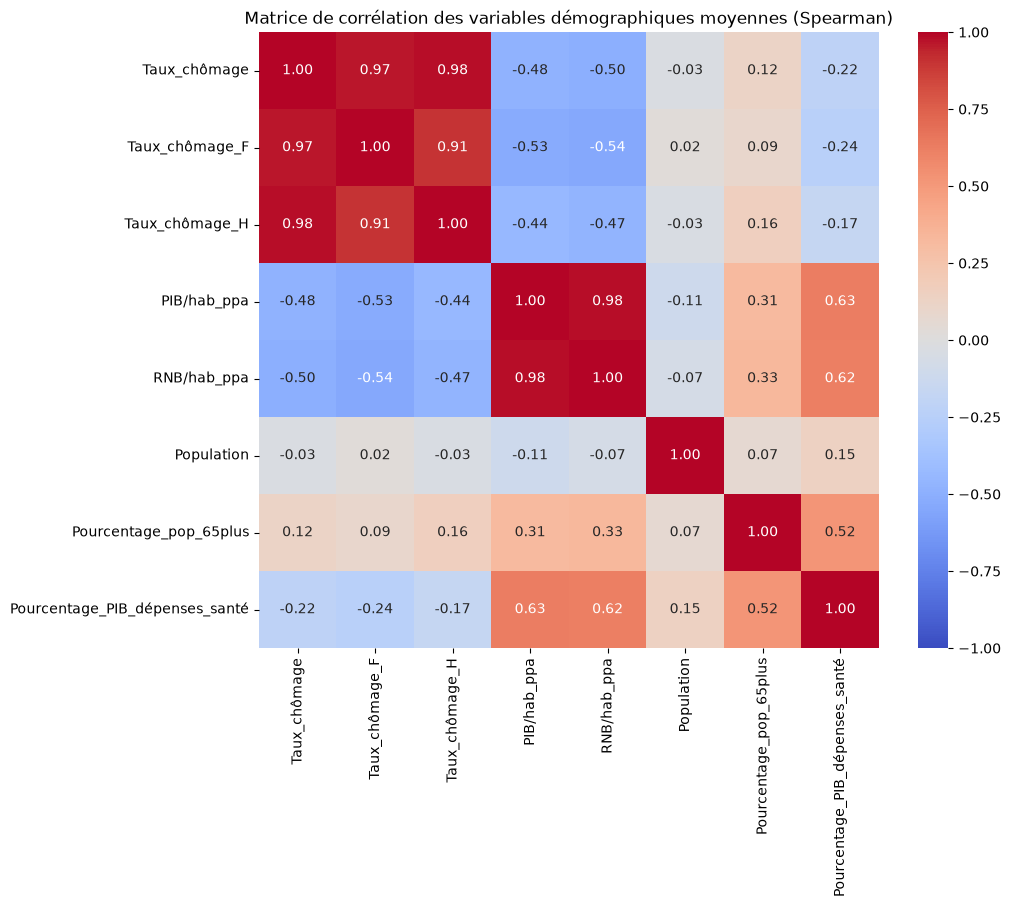

In [15]:
matrice_correlation(df_final, variables_interet, groupe="location_name")

Le tableau de corrélation ci-dessus indique la corrélation entre les différentes variables démographiques retenues moyennées sur la période 1991-2023.
On constate tout d'abord que les indicateurs du chômages sont fortement corrélés positivement, ce qui semble cohérent.
Le PIB/hab est moyennement et négativement corrélé au chômage (-0.48). Il est aussi positivement corrélés aux dépenses de santé(+0.63).

On remarque une très forte corrélation etre PIB et RNB par habitant en PPA (+0.98). Bien que le RNB est considéré par la littérature comme une meilleure mesure du pouvoir d'acaht dans les pays en général, on voit que cette différence est faible au sein des pays de l'OCDE. 
Cette forte corrélation ainsi que l'absence de nombreuses données du RNB nous pousse à retirer le RNB de nos variables explicatives au profit du PIB.

In [16]:
df_final = df_final.drop(columns="RNB/hab_ppa")

##### <u> b. Graphes

Histogrammes : visulalisation de la répartition des données par pays

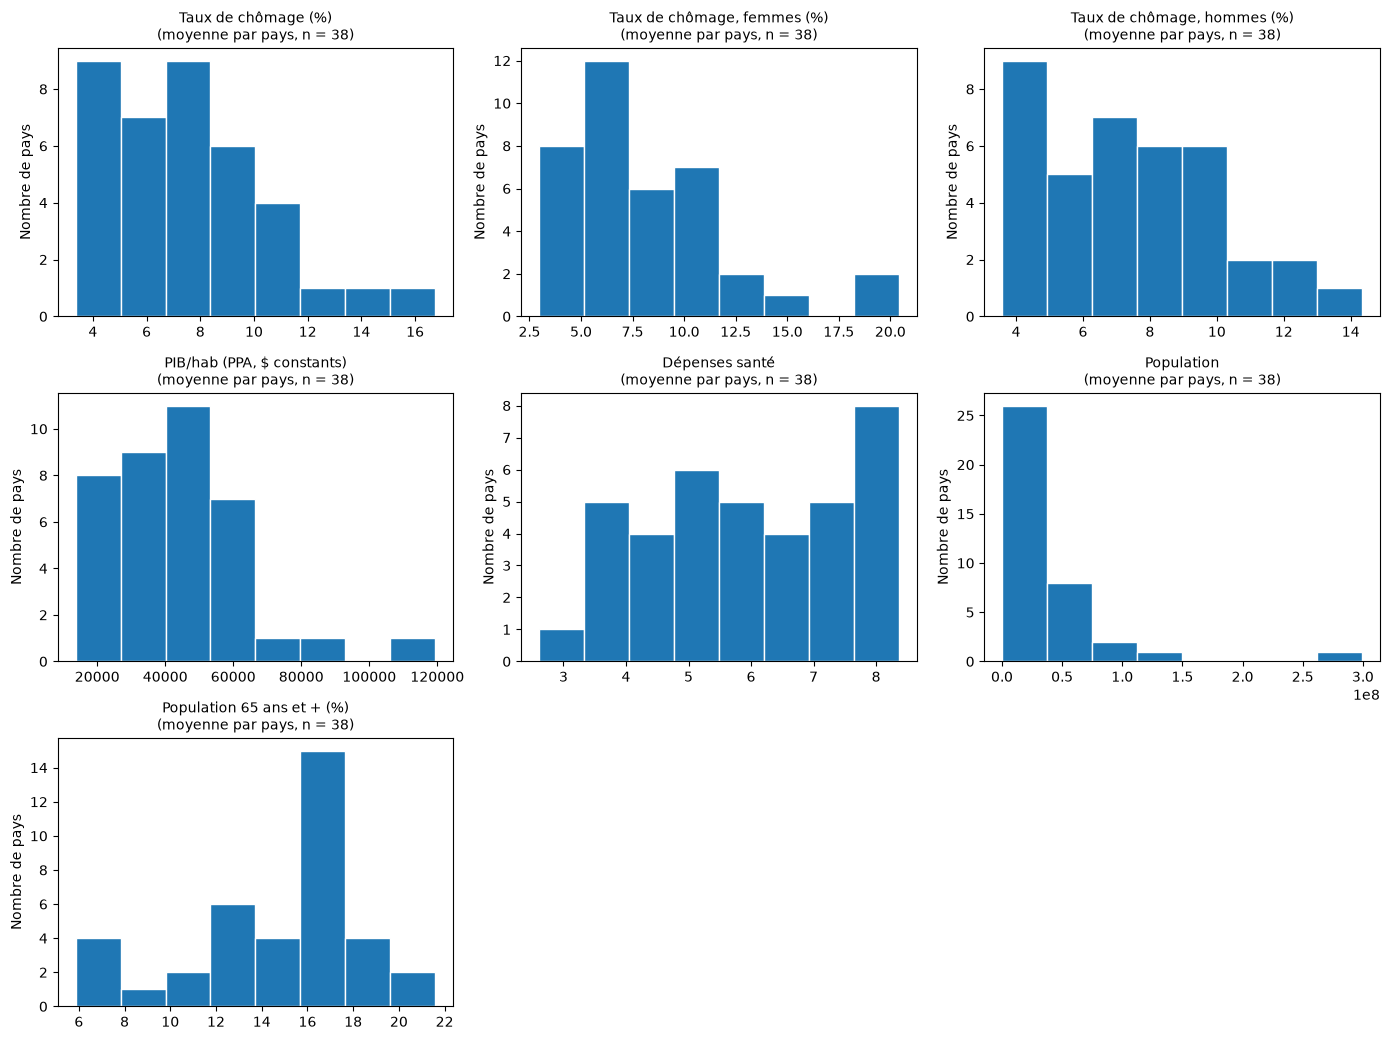

In [17]:
variables = {
    "Taux_chômage": "Taux de chômage (%)",
    "Taux_chômage_F": "Taux de chômage, femmes (%)",
    "Taux_chômage_H": "Taux de chômage, hommes (%)",
    "PIB/hab_ppa": "PIB/hab (PPA, $ constants)",
    "Pourcentage_PIB_dépenses_santé": "Dépenses santé",
    "Population": "Population",
    "Pourcentage_pop_65plus": "Population 65 ans et + (%)",
}

histogrammes_moyennes(df_final_WB, variables)

Les histogrammes ci-dessus décrivent la répartition des 38 pays selon la moyenne de chaque variable sur la période. Les taux de chômage présentent une distribution asymétrique à droite : la plupart des pays ont un taux moyen compris entre 4 % et 10 %, tandis que quelques pays affichent des niveaux nettement plus élevés, en particulier pour le chômage féminin (jusqu'à environ 20 %). Le PIB par habitant est lui aussi asymétrique, avec quelques pays très riches. La population est la variable la plus déséquilibrée : une grande majorité de pays compte moins de 40 millions d'habitants, tandis qu'un pays dépasse les 300 millions. Les dépenses de santé sont réparties de façon plus homogène entre 3 % et 8 % du PIB. La part de la population âgée de 65 ans et plus, moyennée par pays, présente une distribution asymétrique à gauche. La plupart des pays se concentrent entre 12 % et 18 %, avec un regroupement marqué autour de 16-18 % (15 pays sur 38). Un petit groupe de quatre pays se distingue par une proportion de personnes âgées beaucoup plus faible, comprise entre 6 % et 8 %. Cette hétérogénéité reflète des degrés de vieillissement très différents d'un pays à l'autre.

*On représente l'évolution de la moyenne annuelle de chaque variable.*

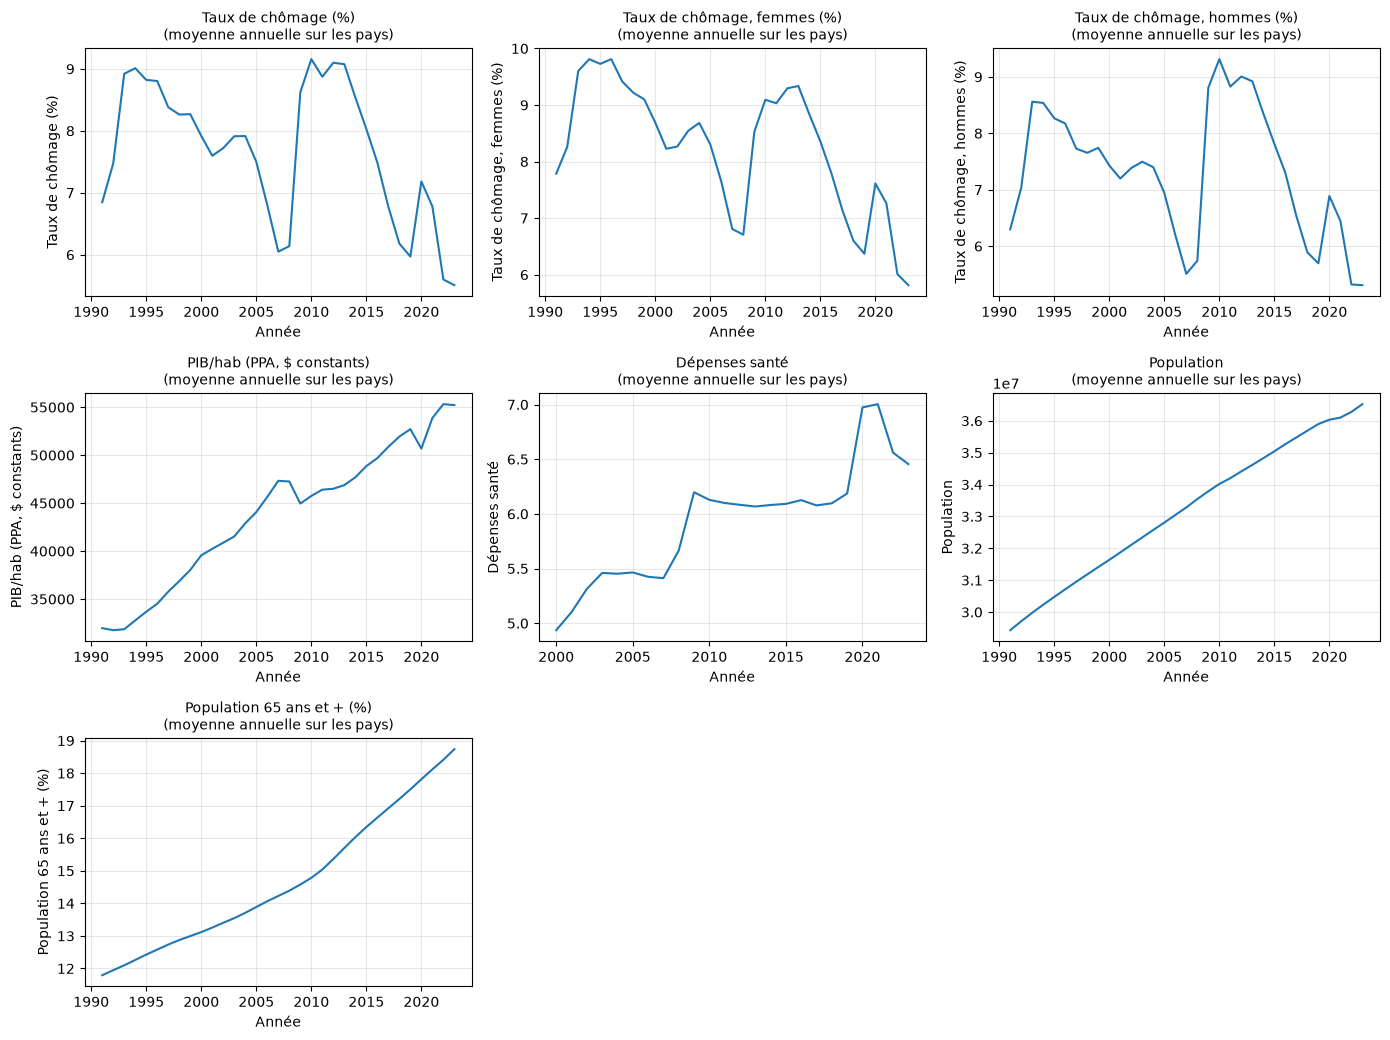

In [18]:
evolutions_moyennes(df_final_WB, variables)

Tout d'abord, les trois courbes de chômage suivent une tendance très semblable : un premier pic entre 1992 et 1998, un second entre 2008 et 2015, et enfin un troisième entre 2019 et 2021.
Le PIB/hab suit une croissance assez linéaire avec néanmoins deux interruptions avec une chute du PIB par habitant en 2007 et 2020.
Les dépenses en santé (en pourcentage du PIB) ressemblent à des plateaux. Une première hausse au début des années 2000 pour atteindre 5.5%, une seconde hausse en 2006 pour atteindre 6.1% du PIB, et enfin une hausse en 2020 pour atteindre 7% du PIB, mais qui est redescendu à 6.5% du PIB en 2021-2022.
Enfin, la population suit une croissance linéaire. La part de plus de 65 ans dans les pays est en croissance, avec une pente qui augmente à partir de 2010. Alors que les plus de 65 ans représentaient 12% de la population en 1990, ils représentent en 2023 presque 19% de la population, ce qui s'explique par le vieillissement démographiques des pays de l'OCDE.

*Trajectoires des pays*

Afin d'avoir des graphiques observables, on choisit de colorer seulement 6 pays parmis les 38, afin d'étudier les différences au sein de ces pays. Les autres pays sont tracés en gris

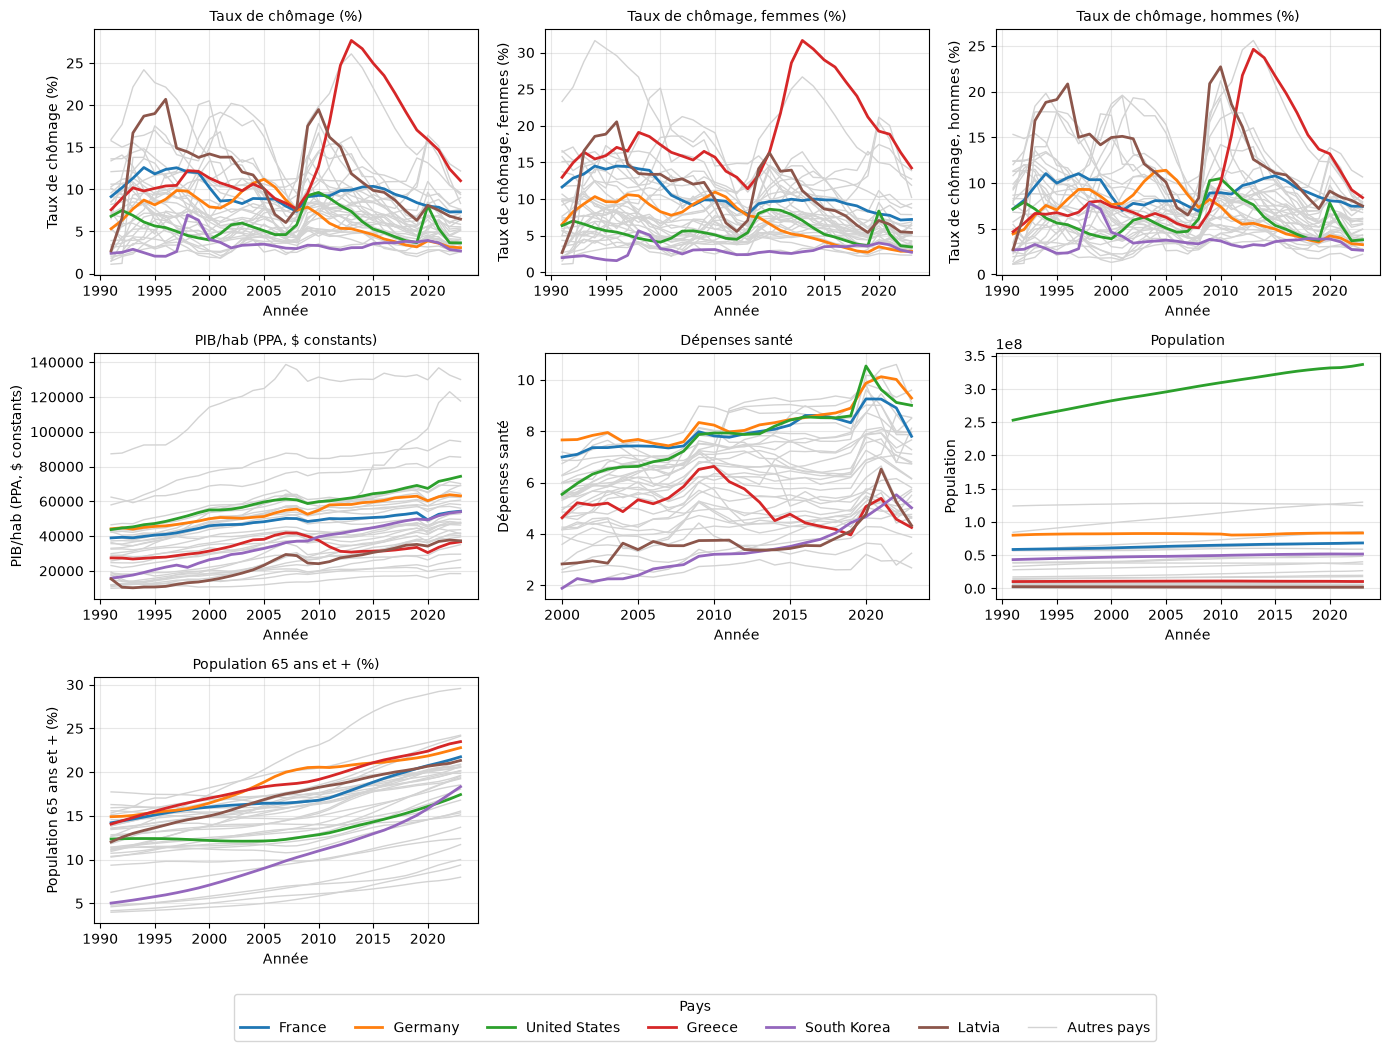

In [19]:
evolutions_par_pays(df_final_WB, variables,
    ["France", "Germany", "United States", "Greece", "South Korea", "Latvia"]
)

Pour mieux visualiser l'hétérogénéité des trajectoires, six pays sont mis en avant sur fond gris représentant les autres pays.
Les 6 pays choisis sont la France, l'Allemagne, les Etats-Unis, la Grèce, la Corée du Sud, et la Lettonie. 
La Grèce se distingue par la crise de 2008-2015 : le chômage atteint près de 28 % en 2013, plus de 30% chez les femmes et le PIB par habitant recule. 
La Lettonie a aussi subi un chômage élevé sur la période 2008-2013, particulièrement chez les hommes, où il atteint près de 23% au pic tandis qu'il ne dépasse pas 15% chez les femmes durant la même période. Cela est d'autant plus intéressant du fait que durant le pic de 1995, ce taux était très proche entre hommes et femmes.
La Corée du Sud présente un chômage faible et stable mais un vieillissement rapide, la part des 65 ans et plus passant d'environ 5 % en 1991 à plus de 17 % en 2023. Néanmoins ce pourcentage est encore inférieur à la plupart des autres pays d'étude.
Les États-Unis se caractérisent par une population nettement supérieure aux autres pays et qui continue de croître, tandis que celles des autres pays sont plus plates, un PIB par habitant élevé et des dépenses de santé parmi les plus fortes, dépassant la France et l'Allemagne vers 2018. 
Enfin, la France et l'Allemagne suivent des trajectoires proches, avec un chômage plus bas en Allemagne depuis 2008 environ.

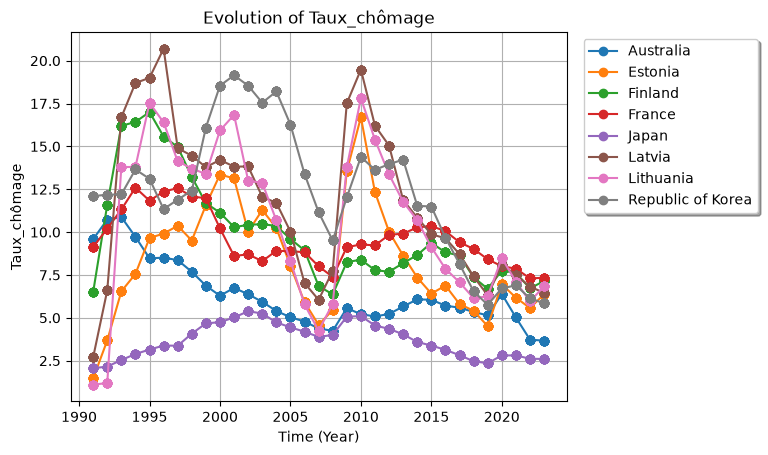

In [20]:
plot_dataframe_multiple_countries_WB(df_final, "Taux_chômage",[1,10,11,12,20,21,22,30]) #Taux de chômage

Les pays européens suivent des tendances similaires en terme de taux de chômage (tous sexes confondus) pour les pays européens et la Corée du Sud. On remarque deux pics notables : un à la fin des années 90 et un second vers 2010.

Tandis que la Corée du Sud subit quant à elle une hausse du taux de chômage au début des années 2000, contrairement aux pays européens considérés ici, mais sa trajectoire se rapproche de celles des pays européens à partir de 2010.

Enfin, l'Australie et le Japon ont des trajectoires différentes avec un taux de chômage qui semble plus stable dans le temps, et plus bas que les autres pays étudiés ici.

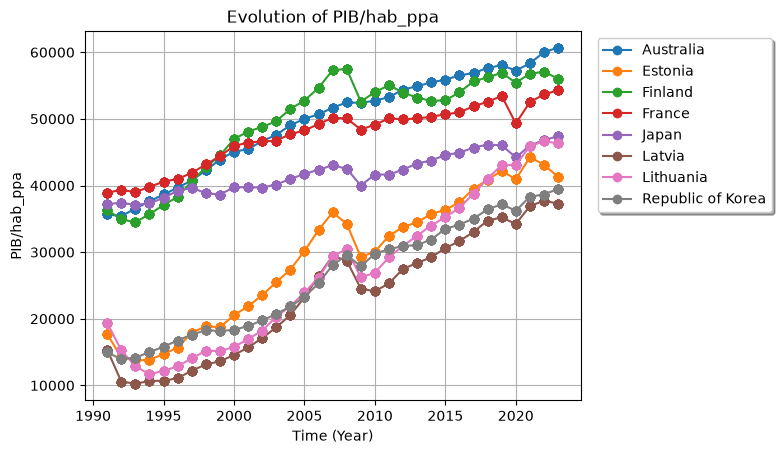

In [21]:
plot_dataframe_multiple_countries_WB(df_final, "PIB/hab_ppa",[1,10,11,12,20,21,22,30]) #PIB par habitant en PPA

Tous les pays considérés ont une évolution très similaire du PIB par habitant (en parité de pouvoir d'achat). On observe une hausse quasi-linéaire dans le temps, bien que tous les pays subissent une baisse du PIB par habitant en 2007. Les pays initialement plus riches (en 1991) ont une hausse moins forte du PIB par habitant que ceux dont le PIB par habitant était initialement plus faible.

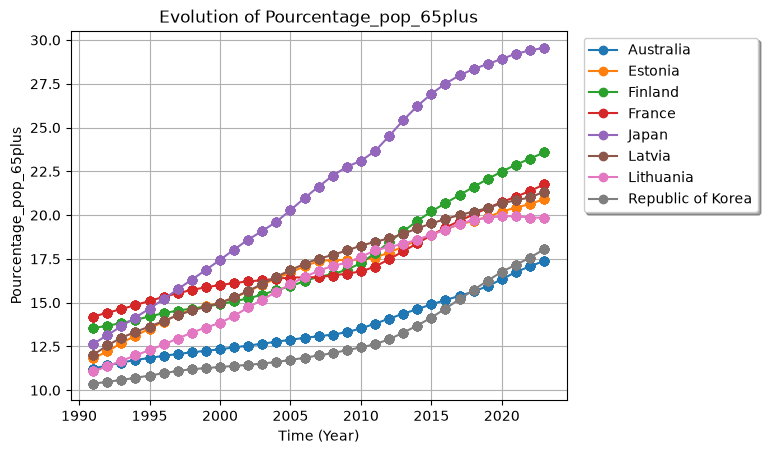

In [22]:
plot_dataframe_multiple_countries_WB(df_final, "Pourcentage_pop_65plus",[1,10,11,12,20,21,22,30]) #Pourcentage de la population âgée de 65 ans et plus

Les pays ont des tendances similaires en terme de part de plus de 65 ans dans la population. On constate ici une augmentation de la part des plus de 65 ans, ce qui est cohérent avec le vieillissement de la population observés dans les pays de l'OCDE. L'effet est particulièrement marqué au Japon où les plus de 65 ans représentaient en 1991 12.5% de la population et près de 30% de la population en 2023.

### **<u> III. Regressions <u>**

#### <u> 1. Regressions simples

Nous consacrons cette section l'étude simple de l'impact du taux de chômage sur la mortalité. Commençons par observer l'évolution du taux de mortalité en fonction du taux de chômage, toutes causes confondues, pour différents pays.

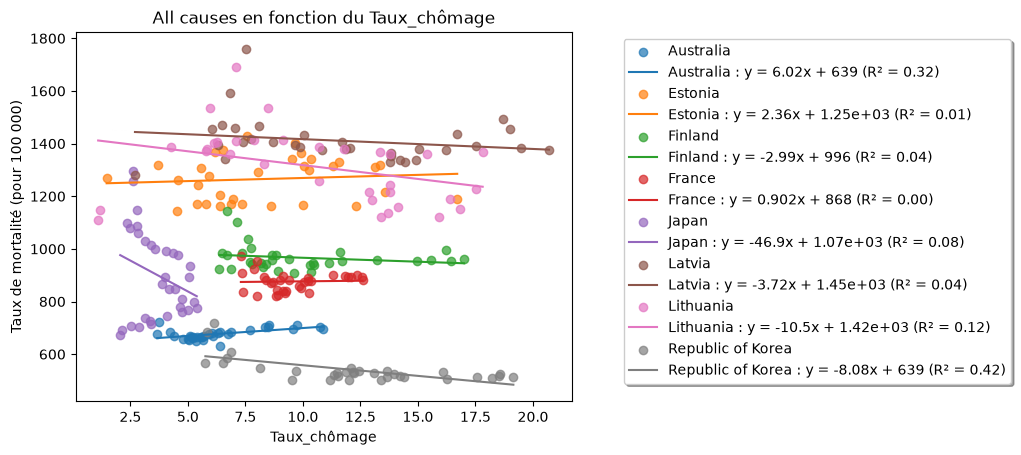

In [23]:
plot_mortalite_demographie_pays(df_final, "Taux_chômage", 1, [1,10,11,12,20,21,22,30])

On observe un grande hétérogénéité entre les pays. L'Australie et l'Estonie ont un coefficient de régression positif : une augmentation de 1%  du taux de chômage en Australie (resp.Estonie) amène à une augmentation du taux de mortalité de 6 (resp.2) pour 100 000 habitants. Au contraire, la Finlande, la Lithuanie, la Lettonie et la Corée du Sud ont un coefficent de régression négatif.
Deux pays se démarquent :
- la France, dont le coefficient de régression est proche de 0. Le taux de chômage et le taux de mortalité semble être décorrelés.
- le Japon, dont le coefficient de régression (-46) est très négatif comparé aux autres pays. 

Enfin, le R² est très faible pour la plupart des pays (0,00 à 0,12), sauf pour la Corée du Sud (0,42) et l'Australie (0,32). Il semblerait que le taux de chômage ne soit pas la meilleure variable pour prédire le taux de mortalité, toutes causes confondues : les relations trouvées ne sont pas très robustes.

Poursuivons avec l'étude de l'évolution du taux de mortalité, toutes causes confondues, en fonction du PIB par habitants.

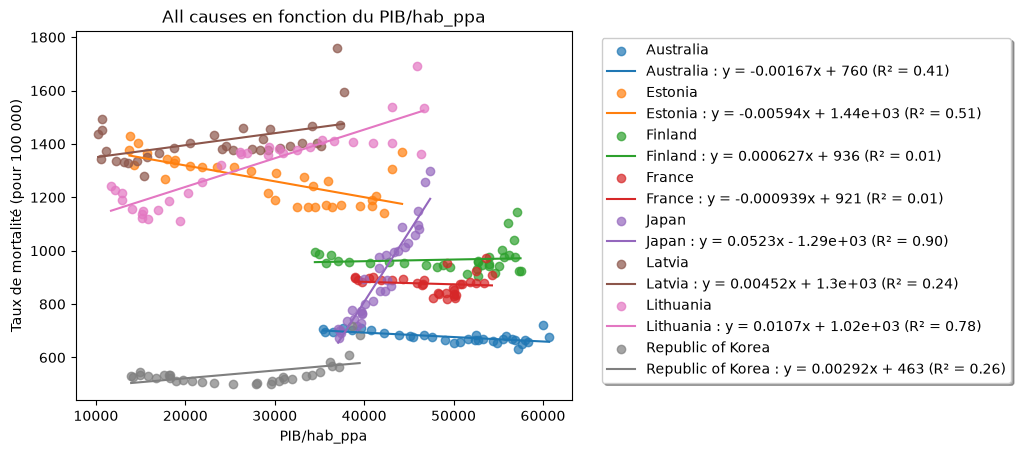

In [24]:
plot_mortalite_demographie_pays(df_final, "PIB/hab_ppa", 1, [1,10,11,12,20,21,22,30])

On remarque dans un premier temps que les R² sont bien plus élevés que pour la régression sur le taux de chômage : le PIB/hab est une variable plus pertinente que le taux de chômage pour prédire le taux de mortalité, toutes causes confondues. De plus, les signes des coefficients de régression sont opposés d'un pays à l'autre. Enfin, la Finlande et la France ont un coefficient de regression nul et un R² très faible : ainsi, pour ces deux pays, le niveau de PIB/habitant n'explique pas le taux de mortalité : la mortalité reste à peu près stable quel que soit le niveau de richesse.

Filtrons maintenant les causes, et ne conservons que le suicide. Commençons par observer l'effet du chômage.

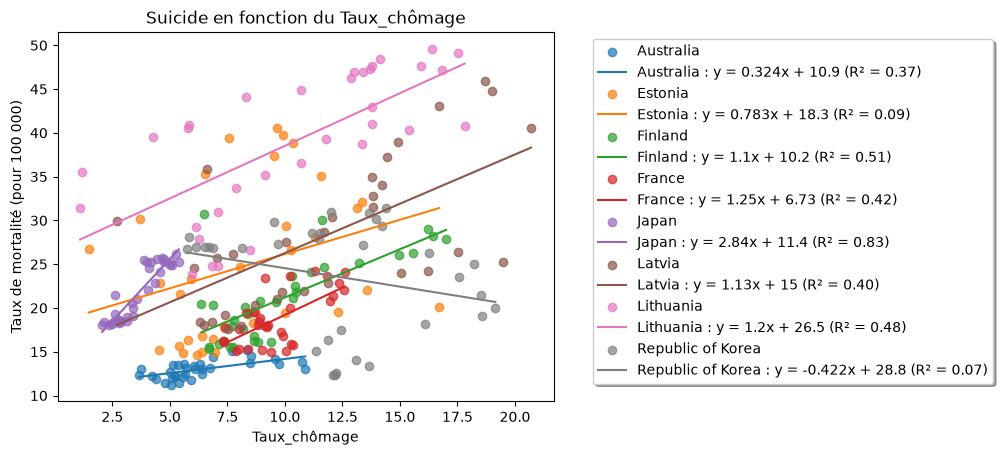

In [25]:
plot_mortalite_demographie_pays(df_final, "Taux_chômage", 7, [1,10,11,12,20,21,22,30])

0n remarque un coefficent de régression positif pour 7 pays sur 8 : plus le chômage est élevé, plus le taux de suicide est élevé. Par exemple, en France, une augmentation de 1% du taux de chômage amène à une augmentation du taux de suicide de 1,15 pour 100 000 habitants. Les R² sont relativement élevés (sauf pour l'Estonie) : le taux de chômage semble judicieux pour expliquer le taux de suicide dans ces pays. 
La Corée fait exception : son coefficient de régression est négatif (-0,42), mais son R² de 0,07 laisse transparaître que le taux de chômage explique y mal les suicides.

Terminons cette section en étudiant l'évolution du taux de suicid en fonction du PIB par habitant.

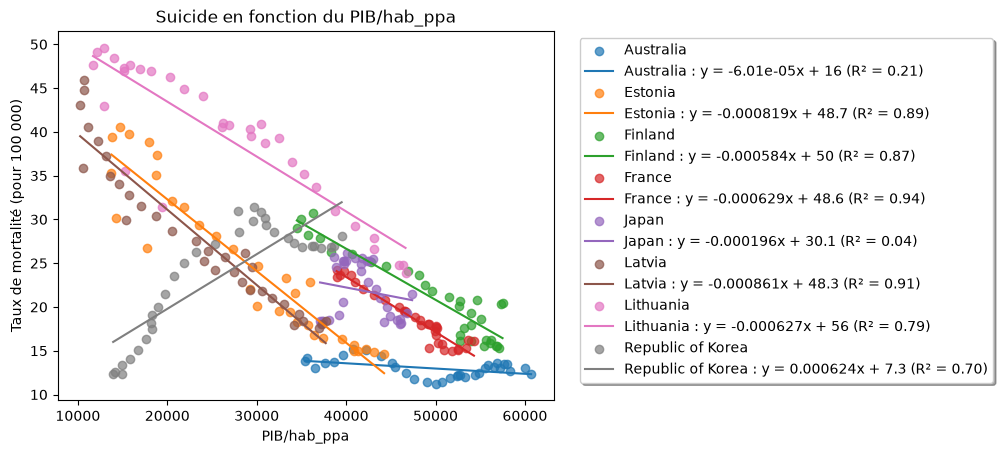

In [26]:
plot_mortalite_demographie_pays(df_final, "PIB/hab_ppa", 7, [1,10,11,12,20,21,22,30])

Tout d'abord, pour tous les pays, le coefficent de la régression du taux de suicide sur le PIB/habitant est du signe opposé de celui de la régression sur le taux de chômage : cela est cohérent. Par exemple, une augmentation de 1% du PIB/habitant en France diminue le taux de suicide de 0,00063 pour 100 000 habitants. La Corée du Sud, tout comme le graphe précédent, suit une trajectoire différente des autres pays. Enfin, les R² sont très élevés comparés aux autres graphes : le PIB/hab est une excellente variable pour prédire le taux de suicide dans la plupart des pays.  

#### <u> 2. Régression multivariée

/workspaces/Projet-Python/modules/Fonctions.py:346: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  df_cause["res_y"] = smf.wls(f"log_value ~ {controles}", data=df_cause, weights=poids).fit().resid * 100
/workspaces/Projet-Python/modules/Fonctions.py:347: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  df_cause["res_x"] = smf.wls(f"chomage ~ {controles}", data=df_cause, weights=poids).fit().resid
/workspaces/Projet-Python/modules/Fonctions.py:334: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  data=df_cause, weights=np.sqrt(df_cause["Population"])).fit(cov_type="cluster", cov_kwds={"groups": df_cause["location_id"]})


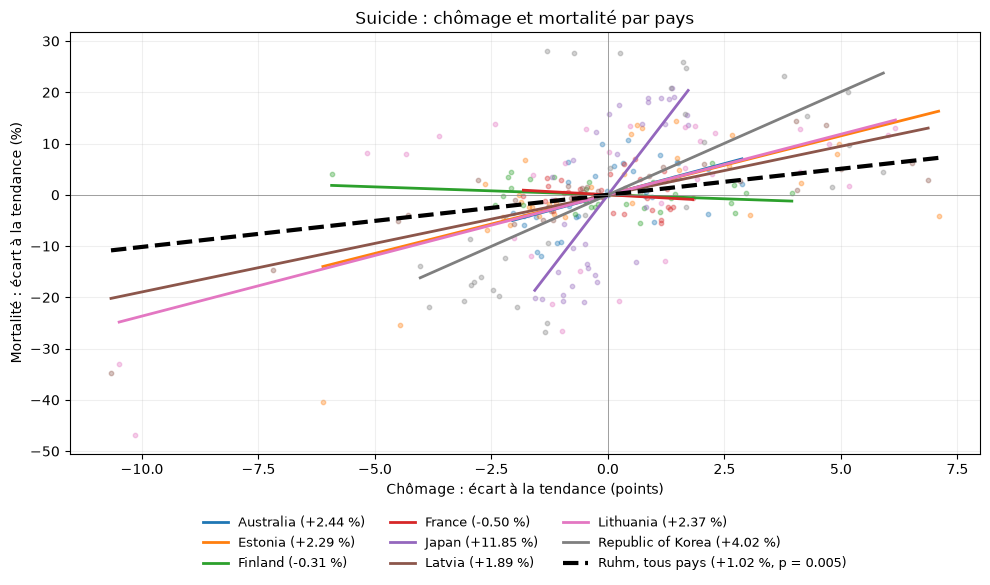

In [27]:
graphe_ruhm(df_final, "Suicide", [1, 10, 11, 12, 20, 21, 22, 30])

Le graphique représente pour les pays considérés, la relation entre chômage et suicide pour chaque pays, une fois neutralisés les effets de la part des 65 ans et plus. La droite en pointillés noirs correspond au coefficient estimé sur l'ensemble des 38 pays de l'OCDE selon la spécification de Ruhm : une hausse d'un point du chômage par rapport à sa tendance est associée à une hausse d'environ 1 % de la mortalité par suicide (p = 0,005).

Cet effet moyen masque toutefois une forte hétérogénéité. La relation est positive dans la plupart des pays : de l'ordre de +2 % par point de chômage dans les pays baltes et en Australie, et plus marquée en Corée du Sud (+4 %) et surtout au Japon (+12 %). Pour ces deux derniers pays, la pente repose sur de faibles variations du chômage.

À l'inverse, la relation est quasiment plate en France (−0,5 %) et en Finlande (−0,3 %). Une explication possible tient au niveau de protection sociale : une assurance chômage plus généreuse et un meilleur accès aux soins pourraient atténuer les conséquences du chômage sur la santé mentale.

### **<u> IV. Etude de l'impact du chômage sur la mortalité pour toutes causes confondues <u>**

##### <u> 1. On s'intéresse ici au taux de mortalité en fonction du taux de chômage pour chaque pays. <u>

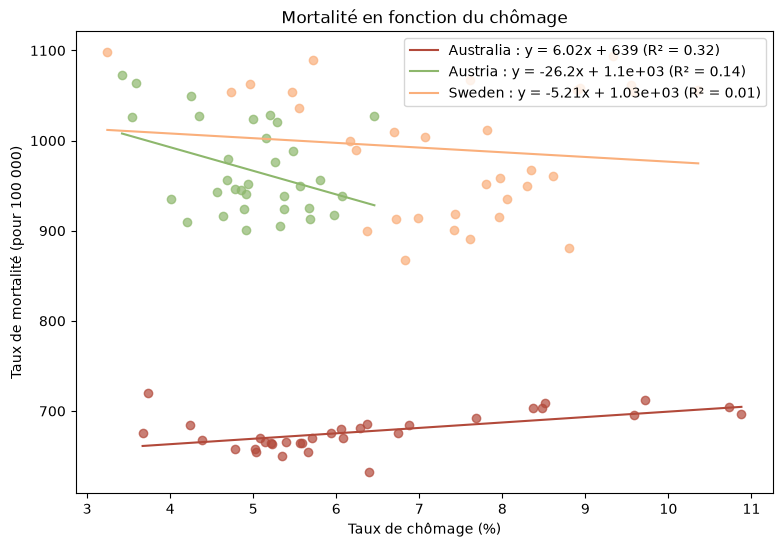

In [28]:
import importlib
import modules.Econometrics.Etudes_all_causes   
importlib.reload(modules.Econometrics.Etudes_all_causes)
from modules.Econometrics.Etudes_all_causes import *

plot_mortalite_chomage_pays(df_final, ["Australia", "Austria", "Sweden"])

On observe que les régressions différent beaucoup d'un pays à l'autre : le signe ainsi que la valeur du coefficient de regression varie selon les pays. 

##### <u> 2. On s'intéresse ici au taux de mortalité en fonction du taux de chômage pour chaque année. <u>

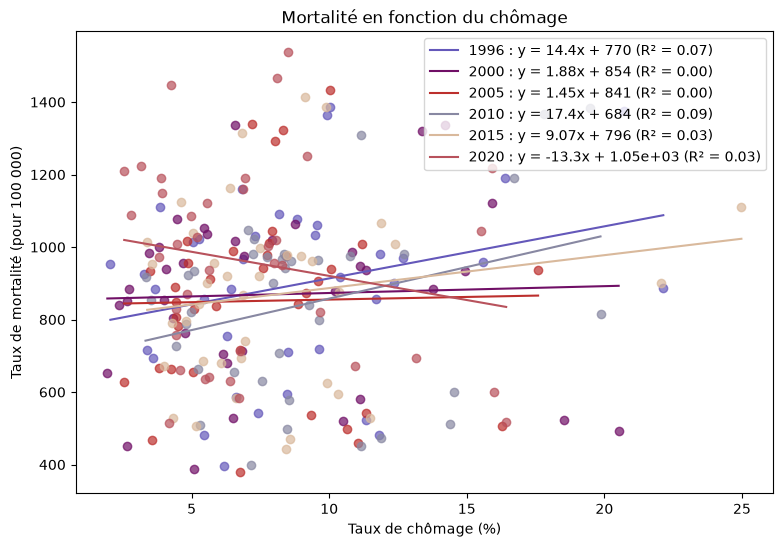

In [29]:
plot_mortalite_chomage_annee(df_final, [1996, 2000, 2005,2010, 2015, 2020])

##### <u> 3. On s'intéresse ici à l'évolution du coefficient de la régession de la mortalité sur le chômage au cours des années. <u>

/workspaces/Projet-Python/modules/Econometrics/Etudes_all_causes.py:96: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


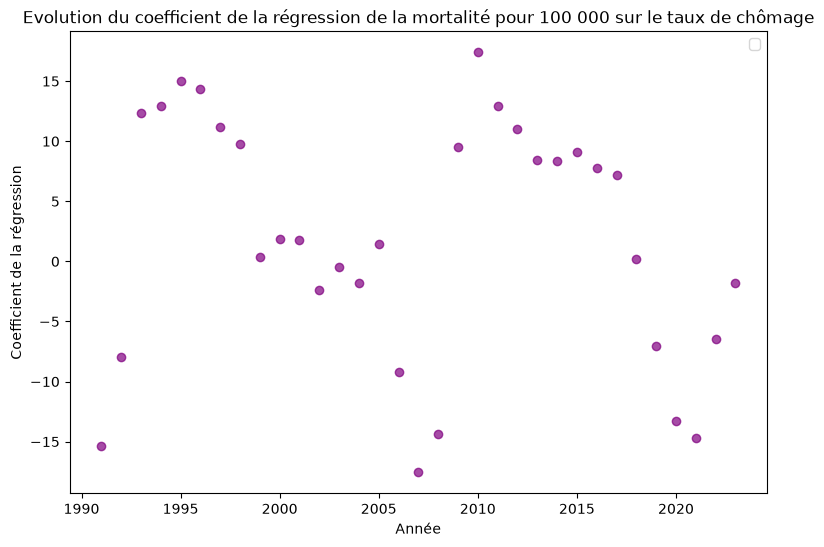

In [30]:
plot_coeff_reg_mortalite_chomage(df_final)

On observe 4 périodes :
- 1991/1992 : le coefficient est négatif. Une augmentation de 1% du taux de chômage diminue la mortalité de 12 pour 100 000 en 1992 et et de 5 pour 100 000 en 1991.
- 1993 à 2019 : le coefficient est positif (sauf 2007). Trois pics : un en 1995 (+1% du taux de chômage amène à +19 morts pour 100 000 habitants), un en 2005 (+1% du taux de chômage amène à +18 morts pour 100 000 habitants) et le plus grand en 2010 (+1% du taux de chômage amène à +26 morts pour 100 000 habitants).
- 2019 à 2021 (période du covid) : le coefficient redevient négatif
- après 2023 : le coefficient repasse positif, mais n'atteint pas les pics des années 1995, 2005 et 2010


On observe donc globalement une tendance positive : outre lors des grand évènements économiques (exemple du Covid-19), une augmentation du taux de chômage amène à une augmentation de la mortalité, TOUTES CAUSES confondues.

Nous décidons donc de nous intéresser spécifiquement aux différentes causes.

### **<u> V. Etude de l'impact du chômage sur la mortalité, causes par causes <u>**

Etude des corrélations

*Ici taux de chômage et mortalité et variation taux de chômage (en points) et variation mortalité, pour chaque cause*

In [31]:
resultat = correlation_par_cause(df_final, "Taux_chômage", "taux_mortalite")
resultat

,corr_niveaux,corr_variation
cause_name,,
All causes,0.05,0.07
Homicide,0.18,0.02
"Liver diseases, cirrhosis",-0.01,-0.09
Major cardiovascular diseases,0.12,-0.04
Malignant neoplasm,-0.15,-0.01
Motor vehicle accidents,0.27,-0.27
Other accidents,0.03,-0.06
Pneumonia and influenza,-0.13,-0.04
Suicide,0.05,0.21


On calcule, pour chaque cause de décès, la corrélation entre le taux de chômage et le taux de mortalité, en niveaux puis en variations annuelles. En niveaux, les corrélations peuvent être trompeuses (tendances communes, différences entre pays) : par exemple, elles changent de signe pour les accidents de la route.
Deux causes de décès ressortent : le suicide (0,21), qui augmente lorsque le chômage augmente, et les accidents de la route (-0,27), qui baissent quand le chômage augmente. 

*Régression du taux de mortalité sur le taux de chômage pour chacune des causes*

In [32]:
resultats = pd.DataFrame([regression(df_final, c) for c in df_final["cause_name"].dropna().unique()],
    index=df_final["cause_name"].dropna().unique(),
    columns=["coef", "p-value"]).round(4)

resultats

,coef,p-value
All causes,0.0016,0.5502
Malignant neoplasm,-0.0005,0.8498
Major cardiovascular diseases,0.0016,0.6787
"Liver diseases, cirrhosis",-0.0068,0.2181
Pneumonia and influenza,-0.0021,0.8712
Motor vehicle accidents,0.0001,0.9803
Suicide,0.0144,0.0036
Other accidents,0.0029,0.5717
Homicide,0.0143,0.0435


Suicide : une augmentation de 1 point de pourcentage du chômage est associée à une hausse moyenne d'environ 1,44 % de la mortalité par suicide. L'effet est statistiquement très robuste (p-value<0.01).

Homicide : une augmentation de 1 point de pourcentage du chômage est associée à une hausse moyenne d'environ 1,43 % de la mortalité par suicide. L'effet est statistiquement robuste (p-value<0.05).

Régression Ruhm

In [33]:
resultats = pd.DataFrame( [regression_ruhm(df_final, c) for c in df_final["cause_name"].dropna().unique()],
    index=df_final["cause_name"].dropna().unique(),
    columns=["coef", "p-value"]).round(4)

resultats

/workspaces/Projet-Python/modules/Fonctions.py:334: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  data=df_cause, weights=np.sqrt(df_cause["Population"])).fit(cov_type="cluster", cov_kwds={"groups": df_cause["location_id"]})
/workspaces/Projet-Python/modules/Fonctions.py:334: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  data=df_cause, weights=np.sqrt(df_cause["Population"])).fit(cov_type="cluster", cov_kwds={"groups": df_cause["location_id"]})
/workspaces/Projet-Python/modules/Fonctions.py:334: SingularMatrixWarning: The design matrix is rank-deficient. The model parameters are not uniquely determined.
  data=df_cause, weights=np.sqrt(df_cause["Population"])).fit(cov_type="cluster", cov_kwds={"groups": df_cause["location_id"]})
/workspaces/Projet-Python/modules/Fonctions.py:334: SingularMatrixWarning: The design matrix is rank-deficient. The model paramete

,coef,p-value
All causes,-0.0016,0.1634
Malignant neoplasm,-0.0017,0.3571
Major cardiovascular diseases,-0.0045,0.0000
"Liver diseases, cirrhosis",-0.0014,0.4532
Pneumonia and influenza,-0.0005,0.8823
Motor vehicle accidents,-0.0096,0.0003
Suicide,0.0102,0.0051
Other accidents,-0.0085,0.0050
Homicide,0.0037,0.5906


En estimant la mortalité selon le taux de chômage de la même manière que Gerdtham et Ruhm (effets fixes pays et année, tendances linéaires par pays, pondération par la racine de la population), nous retrouvons une mortalité globalement procyclique. 

En effet, une hausse d'un point du chômage est associée à une baisse de 0,45 % de la mortalité cardiovasculaire, de 0,96 % de la mortalité routière et de 0,85 % des autres accidents (p < 0,01). 

Le suicide fait exception : il augmente de 1,0 % par point de chômage (p < 0,01). 

L'effet sur la mortalité toutes causes est négatif (−0,16 %) mais non significatif au seuil de 10%. 
Les cancers, les maladies du foie, la pneumonie et l'homicide ne présentent pas de relation significative. Cela peut s'expliquer par le caractère de ces pathologies qui sont longues, et pour lesquelles un choc économique n'affecterait la mortalité qu'avec un décalage de plusieurs années. Notre modèle, ne reliant le taux de chômage et la mortalité de la même année ne permettrait pas d'observer l'effet pour ces maladies.